In [1]:
import sys; sys.path.append("..")
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.db import load_features
from src.features import clean

df = clean(load_features())
print(df.shape, "missing:", df.isna().sum().sum(), "churn rate:", round(df.churn.mean(), 3))
df.describe().T

(7043, 26) missing: 0 churn rate: 0.265


,count,mean,std,min,25%,50%,75%,max
seniorcitizen,7043.0,0.162147,0.368612,0.000,0.000000,0.0000,0.000000,1.000
tenure,7043.0,32.371149,24.559481,0.000,9.000000,29.0000,55.000000,72.000
monthlycharges,7043.0,64.761692,30.090047,18.250,35.500000,70.3500,89.850000,118.750
totalcharges,7043.0,2279.734304,2266.794470,0.000,398.550000,1394.5500,3786.600000,8684.800
churn,7043.0,0.265370,0.441561,0.000,0.000000,0.0000,1.000000,1.000
num_addons,7043.0,2.037910,1.847682,0.000,0.000000,2.0000,3.000000,6.000
no_tech_support,7043.0,0.493114,0.499988,0.000,0.000000,0.0000,1.000000,1.000
avg_monthly_spend,7043.0,64.762906,30.189796,13.775,35.935156,70.3375,90.174158,121.400
charge_trend,7043.0,-0.001213,2.614121,-18.900,-1.159091,0.0000,1.145567,19.125


In [2]:
for col in ["contract", "internetservice", "paymentmethod", "tenure_bucket",
            "techsupport", "paperlessbilling", "seniorcitizen", "num_addons"]:
    print(df.groupby(col)["churn"].agg(["mean", "count"]).round(3), "\n")

                 mean  count
contract                    
Month-to-month  0.427   3875
One year        0.113   1473
Two year        0.028   1695 

                  mean  count
internetservice              
DSL              0.190   2421
Fiber optic      0.419   3096
No               0.074   1526 

                            mean  count
paymentmethod                          
Bank transfer (automatic)  0.167   1544
Credit card (automatic)    0.152   1522
Electronic check           0.453   2365
Mailed check               0.191   1612 

                mean  count
tenure_bucket              
0-12           0.474   2186
13-24          0.287   1024
25-48          0.204   1594
49+            0.095   2239 

              mean  count
techsupport              
No           0.312   4999
Yes          0.152   2044 

                   mean  count
paperlessbilling              
No                0.163   2872
Yes               0.336   4171 

                mean  count
seniorcitizen              
0

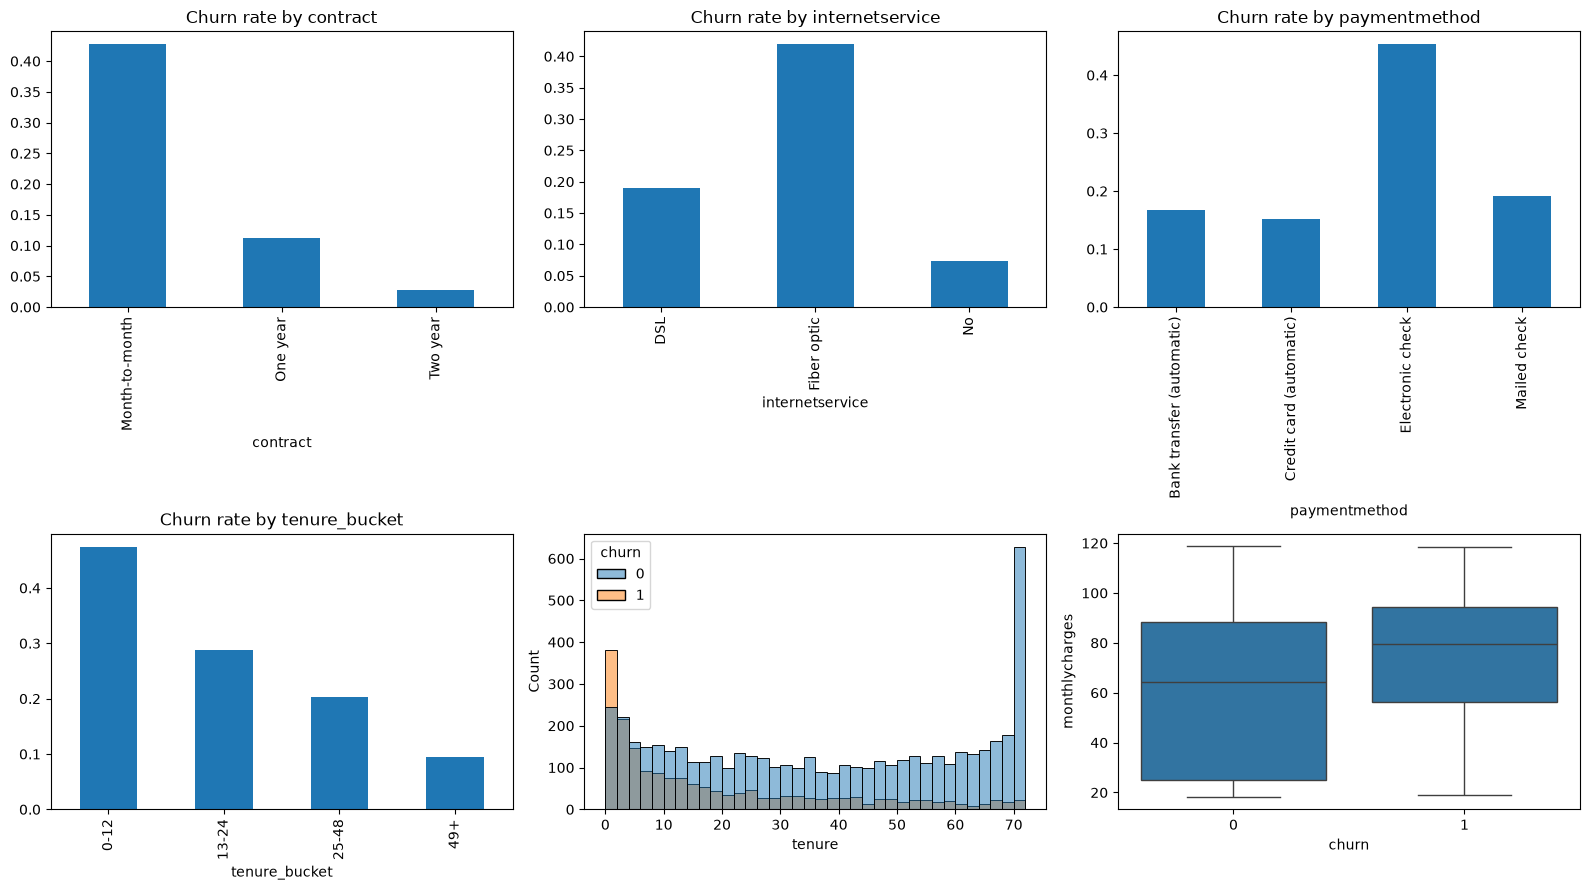

In [3]:
fig, ax = plt.subplots(2, 3, figsize=(16, 9))
for a, col in zip(ax.flat[:4], ["contract", "internetservice", "paymentmethod", "tenure_bucket"]):
    df.groupby(col)["churn"].mean().plot.bar(ax=a, title=f"Churn rate by {col}")
sns.histplot(data=df, x="tenure", hue="churn", bins=36, ax=ax[1, 1])
sns.boxplot(data=df, x="churn", y="monthlycharges", ax=ax[1, 2])
plt.tight_layout(); plt.savefig("../docs/eda_overview.png", dpi=150)

Key EDA Insights-

Dataset Overview: Analyzing 7,043 customers across 26 features with 0 missing values and a 26.5% overall churn rate.

Contract Risk: Month-to-month contracts suffer from 42.7% churn, whereas 2-year contracts drop churn to 2.8%.

Service Tier: Fiber Optic users experience high churn (41.9%) compared to DSL (19.0%) and No Internet (7.4%).

Payment Channels: Electronic check users exhibit the highest churn risk (45.3%); automated payment methods stay under 17%.

Tenure Vulnerability: New customers (0--12 months) have the highest churn rate at 47.4%, stabilizing after 48 months (9.5%).

Price Sensitivity: Churned users show a significantly higher median monthly charge (approx $80) than retained users (approx $60).